# Week 2 - Histograms with segmentation
Necessary imports

In [1]:
from __future__ import annotations
import cv2
import matplotlib.pyplot as plt
import pickle
from dataclasses import dataclass
from pathlib import Path

import numpy as np
from scipy.ndimage import gaussian_filter1d, binary_fill_holes, gaussian_filter1d

## 0. Image and ground truth loading
Code snippet from week1 code so it stays with a persistent method

In [2]:
@dataclass(frozen=True)
class ImageDataset:
    """Image paths paired with integer IDs in deterministic filename order."""

    paths: tuple[Path, ...]
    ids: np.ndarray

    def __len__(self) -> int:
        return len(self.paths)


def image_id(path: Path) -> int:
    """Parse IDs from both `00012.jpg` and `bbdd_00012.jpg`."""
    return int(path.stem.rsplit("_", 1)[-1])


def load_image_dataset(directory: str | Path) -> ImageDataset:
    directory = Path(directory)
    # Sorting is essential: submission row i must correspond to query image i.
    paths = tuple(sorted(directory.glob("*.jpg")))
    if not paths:
        raise FileNotFoundError(f"No JPG images found in {directory}")
    ids = np.asarray([image_id(path) for path in paths], dtype=int)
    if len(np.unique(ids)) != len(ids):
        raise ValueError(f"Duplicate image IDs found in {directory}")
    return ImageDataset(paths=paths, ids=ids)


def load_ground_truth(path: str | Path) -> list[list[int]]:
    with Path(path).open("rb") as stream:
        values = pickle.load(stream)
    return [[int(image_id) for image_id in relevant] for relevant in values]


In [3]:
train_dataset = load_image_dataset("../data/BBDD")
ground_truth = load_ground_truth("../data/qsd1_w1/gt_corresps.pkl")

## Task 1. Simple image segmentation and histogramization

Simple pyramid segmentation which splits an (HxW) image onto NxN blocks of size (W/N, H/N). Histograms are computed on normalized lab space as in the last week code and normalized before being concatenated onto a 1D $b*N^2*3$ size vector (b being the bin size)

In [4]:
def simple_segment_and_histogram(img, level, bins=48, plot=False, normalize=True, weights=None):
    
    """
    Segment a BGR image into a level x level grid and compute
    concatenated L, A, B histograms for every block.

    Returns
    -------
    np.ndarray
        Flattened array of length level * level * 3 * bins
        (reshape to (level * level, 3 * bins) to get one row per block).
    """

    h, w = img.shape[:2]
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)

    histograms = np.empty((level * level, 3 * bins), dtype=np.float32)

    y_edges = np.linspace(0, h, level + 1, dtype=int)
    x_edges = np.linspace(0, w, level + 1, dtype=int)

    for i in range(level):
        for j in range(level):
            idx = i * level + j
            block = lab[y_edges[i]:y_edges[i + 1],
                        x_edges[j]:x_edges[j + 1]]

            channel_histograms = []
            for channel in range(3):
                hist = cv2.calcHist([block], [channel], None,
                                    [bins], [0, 256]).ravel()
                if normalize:
                    hist /= max(hist.sum(), 1e-12)
                channel_histograms.append(hist)

            histograms[idx] = np.concatenate(channel_histograms)

    if plot:
        fig = plt.figure(figsize=(4 * (level + 1), 2.8 * level),
                         layout="constrained")
        outer = fig.add_gridspec(1, 2, width_ratios=[1, level])

        # ---- Left: image with the segmentation grid ----
        ax_img = fig.add_subplot(outer[0])
        ax_img.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

        # Block boundaries sit between pixels, hence the -0.5 offset.
        for x in x_edges[1:-1]:
            ax_img.axvline(x - 0.5, color="red", linewidth=1.5)
        for y in y_edges[1:-1]:
            ax_img.axhline(y - 0.5, color="red", linewidth=1.5)

        # Label each block at its center.
        for i in range(level):
            for j in range(level):
                cx = (x_edges[j] + x_edges[j + 1]) / 2
                cy = (y_edges[i] + y_edges[i + 1]) / 2
                ax_img.text(cx, cy, f"({i},{j})", color="white",
                            ha="center", va="center", fontsize=9,
                            bbox=dict(facecolor="black", alpha=0.5,
                                      edgecolor="none", pad=1.5))

        ax_img.set_title(f"Segmentation ({level}x{level} blocks)")
        ax_img.axis("off")

        # ---- Right: one histogram plot per block ----
        inner = outer[1].subgridspec(level, level)
        channel_names = ["L", "a", "b"]
        channel_colors = ["black", "green", "blue"]

        for i in range(level):
            for j in range(level):
                idx = i * level + j
                ax = fig.add_subplot(inner[i, j])

                for c, (name, color) in enumerate(
                        zip(channel_names, channel_colors)):
                    start, end = c * bins, (c + 1) * bins
                    ax.plot(np.arange(start, end),
                            histograms[idx, start:end],
                            color=color, linewidth=1.3, label=name)

                ax.axvline(bins - 0.5, color="gray",
                           linestyle="--", linewidth=0.8)
                ax.axvline(2 * bins - 0.5, color="gray",
                           linestyle="--", linewidth=0.8)

                ax.set_title(f"Block ({i}, {j})", fontsize=10)
                ax.set_xlim(0, 3 * bins - 1)
                ax.set_xticks([bins / 2 - 0.5,
                               1.5 * bins - 0.5,
                               2.5 * bins - 0.5])
                ax.set_xticklabels(channel_names)
                ax.grid(alpha=0.2)

                if j == 0:
                    ax.set_ylabel("Frequency" if normalize
                                  else "Pixel count")
                if i == 0 and j == level - 1:
                    ax.legend(fontsize=8, loc="upper right")

        plt.show()

    return histograms.flatten()

### Tests on images
To ensure that the image segmentation and histogramisation is going correctly, some tests and plotting are done on arbitrary images

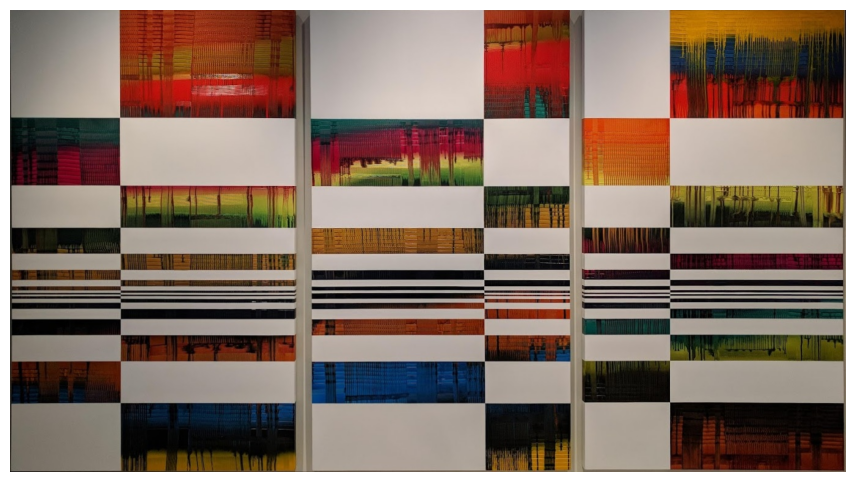

In [5]:
image = cv2.imread(train_dataset.paths[0].as_posix())
plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


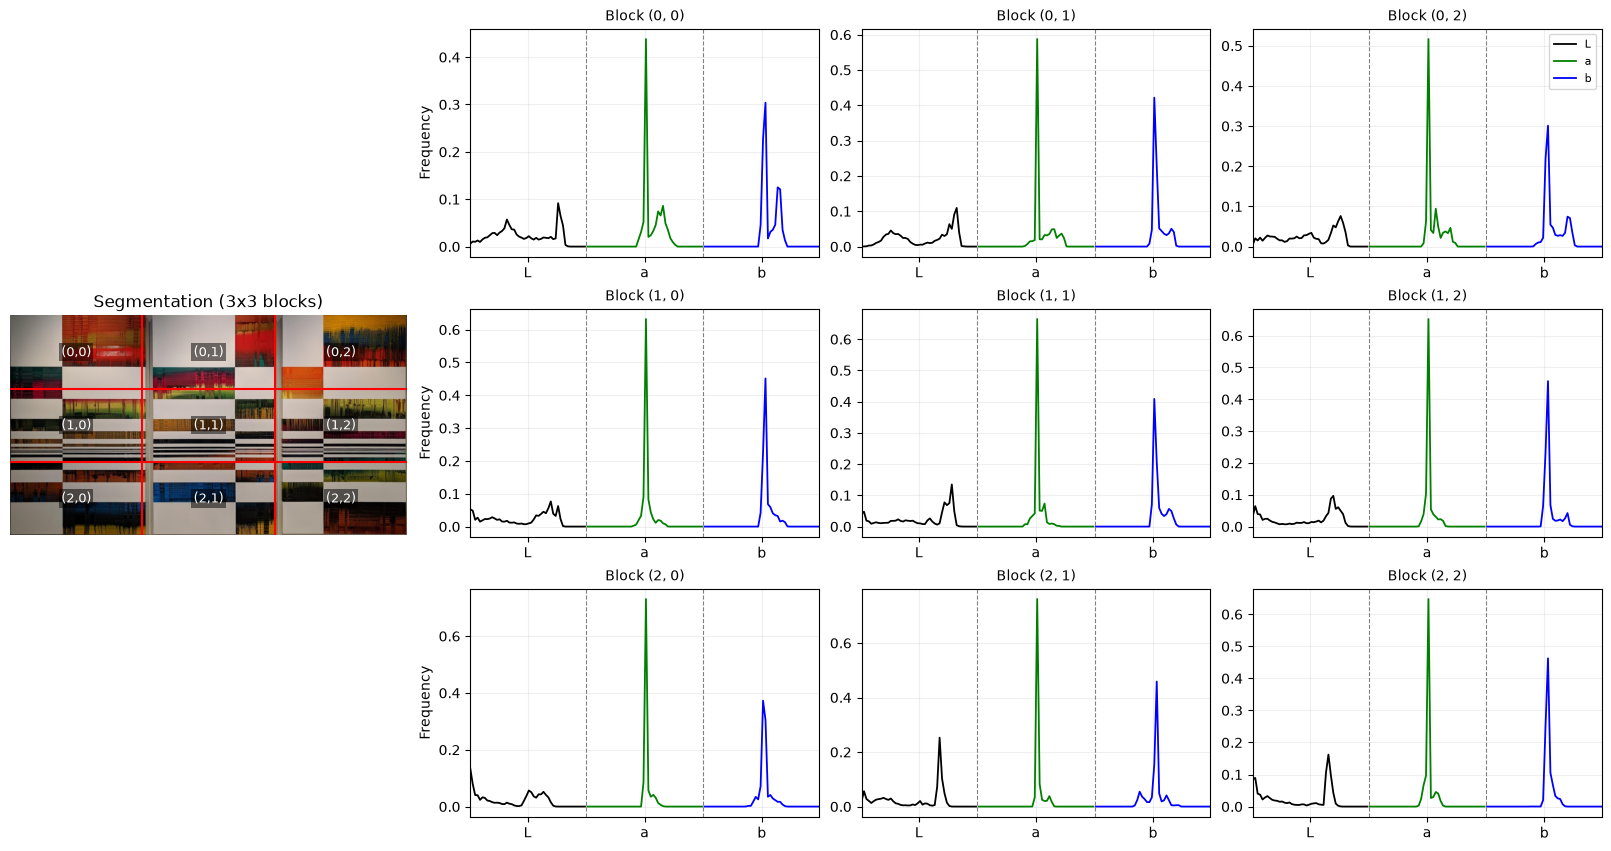

In [6]:
test_hist = simple_segment_and_histogram(image, level=3, plot=True)

In [7]:
test_hist.shape

(1296,)

## Task 2 - Query system with block histograms

We run the same 30 development queries (QSD1-W2 is the same set as QSD1-W1) using the block histograms from Task 1, measure mAP@1 and mAP@5, and compare with our best W1 result (global tuned Lab histogram, Hellinger: mAP@1 0.700, mAP@5 0.728).

In [8]:
query_dataset = load_image_dataset("../data/qsd1_w1")      
read = lambda p: cv2.imread(p.as_posix())
q_imgs  = [read(p) for p in query_dataset.paths]
db_imgs = [read(p) for p in train_dataset.paths]
print(len(db_imgs), len(q_imgs), len(ground_truth))       

287 30 30


### Distance and evaluation
Same as W1: Hellinger distance (the best measure in W1) and mAP@K. Each query has one correct painting, so AP@K = 1/rank if it appears in the top K, and 0 otherwise.

In [9]:
def hellinger(q, D):
    return np.sqrt(((np.sqrt(q) - np.sqrt(D)) ** 2).sum(axis=1))

def map_at_k(results, gt, k):
    aps = []
    for res, rel in zip(results, gt):
        ap, hits = 0.0, 0
        for r, img_id in enumerate(res[:k], start=1):
            if img_id in rel:
                hits += 1
                ap += hits / r
        aps.append(ap / min(len(rel), k))
    return float(np.mean(aps))

### Block histograms with the W1 descriptor
We use the best descriptor from W1: Lab, 48 bins per channel, Gaussian smoothing along the bins (σ 0.5), channel weights (L, a, b = 0.125, 0.5, 0.375) and Hellinger distance. Now it is computed per block: the image is split into N×N blocks, each block gets its own histograms, and they are concatenated. The argument `levels` also lets us join several grid levels (spatial pyramid) in one descriptor.

The 1x1 grid is the W1 global histogram, so its result must match W1 (mAP@1 0.700, mAP@5 0.728). This checks the pipeline, and every other row is compared with it.

In [10]:
def descriptor(img, levels=(1,), bins=48, sigma=0.5, weights=(0.125, 0.5, 0.375)):
    out = []
    for level in levels:
        h = simple_segment_and_histogram(img, level, bins=bins).reshape(level*level, 3, bins)
        if sigma > 0:
            h = gaussian_filter1d(h, sigma, axis=2, mode="nearest")   # smooth along the bins
            h = h / h.sum(axis=2, keepdims=True)                      # normalise each channel again
        h = h * np.asarray(weights)[None, :, None]                    # L, a, b weights
        out.append(h.ravel() / h.sum())
    return np.concatenate(out) / len(levels)

### Which grid size works best?
We test grids from 1x1 (the W1 global histogram) to 6x6, and two pyramids (several levels joined). All use Hellinger.

In [11]:
configs = {"global (1)": (1,), "2x2": (2,), "3x3": (3,), "4x4": (4,),
           "5x5": (5,), "6x6": (6,),
           "pyramid 1-2": (1, 2), "pyramid 1-2-3": (1, 2, 3)}
rows, store = [], {}
for name, lv in configs.items():
    D = np.array([descriptor(im, lv) for im in db_imgs])
    res = [[int(train_dataset.ids[i]) for i in np.argsort(hellinger(descriptor(im, lv), D), kind="stable")[:10]]
           for im in q_imgs]
    rows.append((name, map_at_k(res, ground_truth, 1), map_at_k(res, ground_truth, 5)))
    store[name] = res
    print(f"{name:<14} mAP@1 {rows[-1][1]:.3f}   mAP@5 {rows[-1][2]:.3f}")

global (1)     mAP@1 0.700   mAP@5 0.728
2x2            mAP@1 0.700   mAP@5 0.767
3x3            mAP@1 0.800   mAP@5 0.843
4x4            mAP@1 0.833   mAP@5 0.867
5x5            mAP@1 0.867   mAP@5 0.892
6x6            mAP@1 0.867   mAP@5 0.892
pyramid 1-2    mAP@1 0.667   mAP@5 0.754
pyramid 1-2-3  mAP@1 0.700   mAP@5 0.778


### Results
The `global (1)` row reproduces our W1 result (0.700 / 0.728), so the rows below are directly comparable with it.

| descriptor | mAP@1 | mAP@5 |
|---|---|---|
| global (W1) | 0.700 | 0.728 |
| 2x2 | 0.700 | 0.767 |
| 3x3 | 0.800 | 0.843 |
| 4x4 | 0.833 | 0.867 |
| **5x5** | **0.867** | **0.892** |
| 6x6 | 0.867 | 0.892 |
| pyramid 1-2 | 0.667 | 0.754 |
| pyramid 1-2-3 | 0.700 | 0.778 |

- Block histograms are better than the global histogram: mAP@1 goes from 0.700 to 0.867 with 5x5 blocks (5 more queries correct out of 30). A global histogram only tells which colours are in the painting. Blocks also tell where they are.
- The improvement stops at 5x5: 6x6 gives the same result, so we choose **5x5** (3,600 values per image, instead of 5,184).
- Pyramids are not better than a single fine grid. The coarse levels dilute the spatial detail.
- Caution: the grid size was chosen on the same 30 queries, and 4x4, 5x5 and 6x6 differ by only one query each. So we only claim that blocks help and that results plateau around 5x5, not that 5x5 is clearly better than 4x4.

### Examples of retrieval (5x5)
For each query we show the top 5 results. Green border = correct painting, red = wrong.

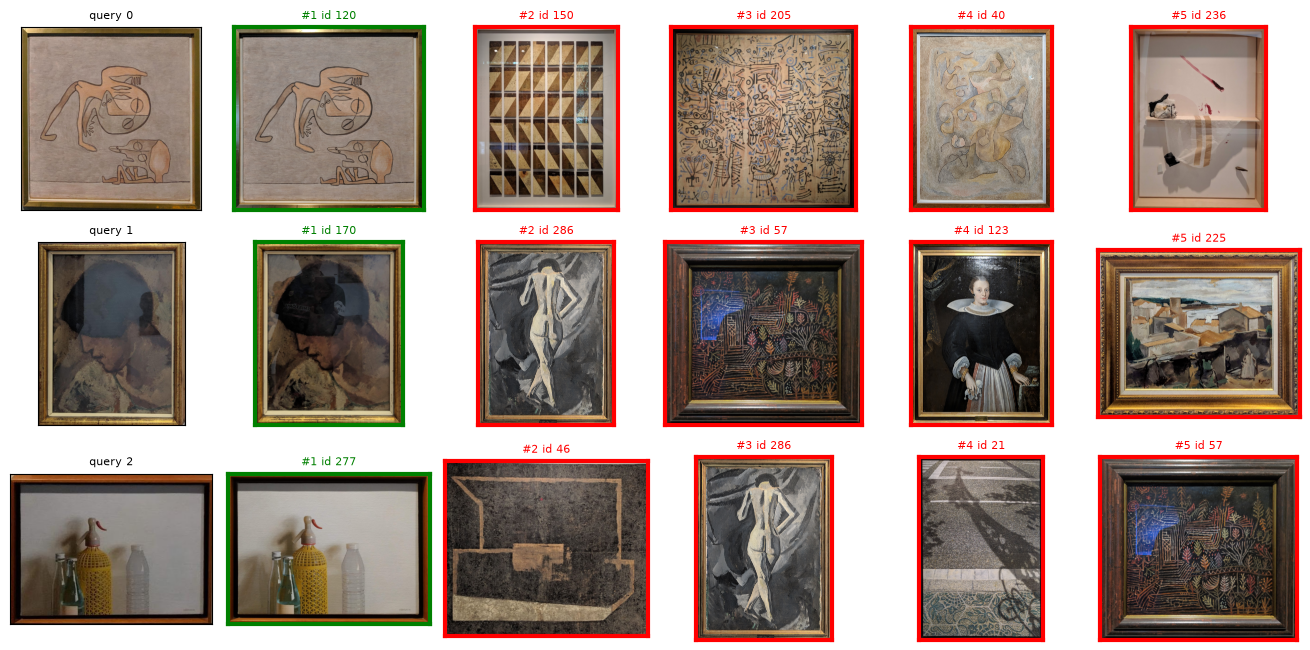

In [12]:
def show_retrievals(res, q_imgs, db_imgs, db_ids, gt, query_ids, k=5):
    id2 = {int(i): n for n, i in enumerate(db_ids)}
    fig, axes = plt.subplots(len(query_ids), k + 1, figsize=(2.2*(k+1), 2.2*len(query_ids)))
    axes = np.atleast_2d(axes)
    for r, qi in enumerate(query_ids):
        axes[r, 0].imshow(cv2.cvtColor(q_imgs[qi], cv2.COLOR_BGR2RGB))
        axes[r, 0].set_title(f"query {qi}", fontsize=8)
        for c, img_id in enumerate(res[qi][:k], 1):
            axes[r, c].imshow(cv2.cvtColor(db_imgs[id2[img_id]], cv2.COLOR_BGR2RGB))
            col = "green" if img_id in gt[qi] else "red"
            axes[r, c].set_title(f"#{c} id {img_id}", fontsize=8, color=col)
            for s in axes[r, c].spines.values():
                s.set_edgecolor(col); s.set_linewidth(3)
        for a in axes[r]:
            a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.show()

show_retrievals(store["5x5"], q_imgs, db_imgs, train_dataset.ids, ground_truth, [0, 1, 2])

### Failure analysis
We look at the queries where the correct painting is not at rank 1 with the 5x5 descriptor.

In [13]:
best = "5x5"
fails = []
for i, (res, gt) in enumerate(zip(store[best], ground_truth)):
    pos = next((r for r, img_id in enumerate(res, 1) if img_id in gt), None)   # None = not in top 10
    if pos != 1:
        fails.append(i)
        print(f"query {i:>2}  gt id {gt[0]:>3}  correct image at rank: {pos}")
print("\nfailing at rank 1:", len(fails), "of", len(ground_truth))

query  5  gt id 274  correct image at rank: None
query 17  gt id  47  correct image at rank: 2
query 26  gt id 238  correct image at rank: 4
query 28  gt id  86  correct image at rank: None

failing at rank 1: 4 of 30


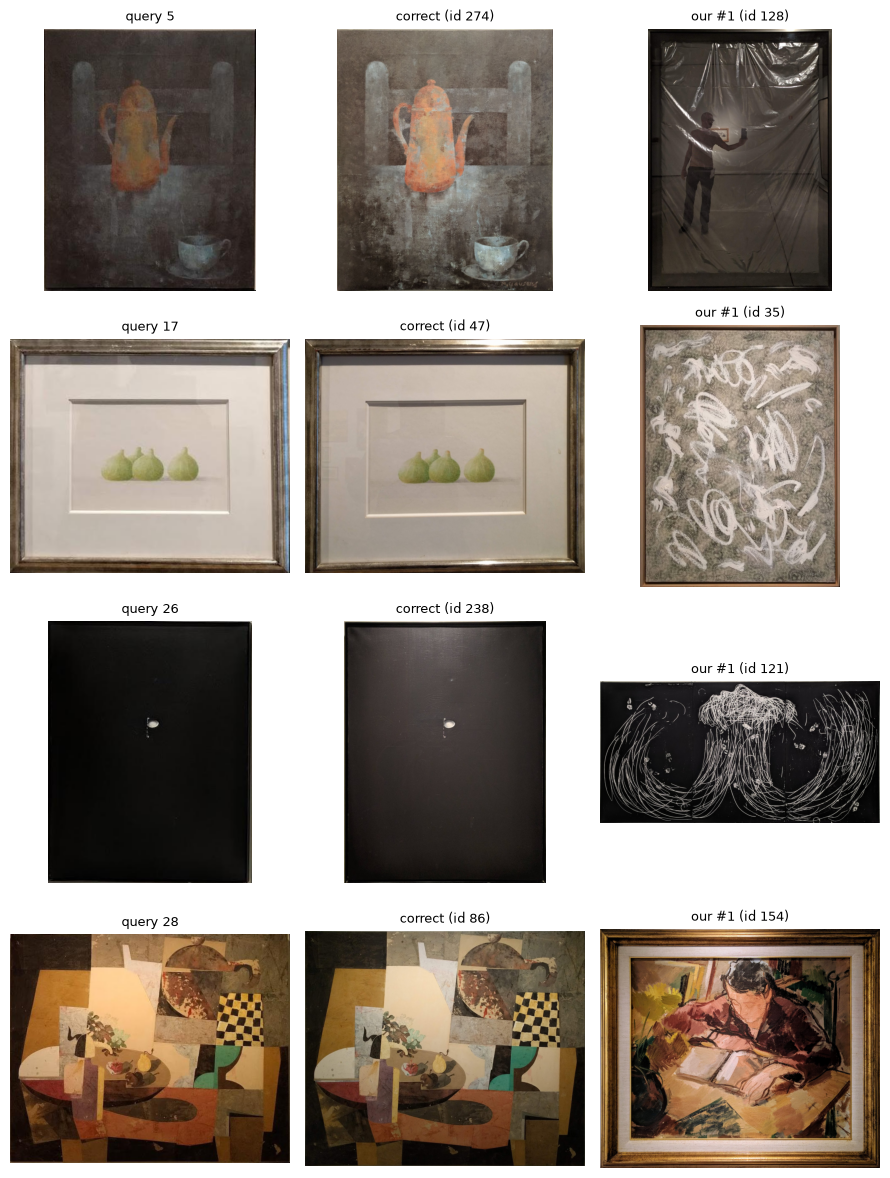

In [14]:
id2 = {int(i): n for n, i in enumerate(train_dataset.ids)}
fig, axes = plt.subplots(len(fails[:4]), 3, figsize=(9, 3 * len(fails[:4])))
axes = np.atleast_2d(axes)
for r, qi in enumerate(fails[:4]):
    wrong_id = store[best][qi][0]
    for c, (img, title) in enumerate([
            (q_imgs[qi], f"query {qi}"),
            (db_imgs[id2[ground_truth[qi][0]]], f"correct (id {ground_truth[qi][0]})"),
            (db_imgs[id2[wrong_id]], f"our #1 (id {wrong_id})")]):
        axes[r, c].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[r, c].set_title(title, fontsize=9); axes[r, c].axis("off")
plt.tight_layout(); plt.show()

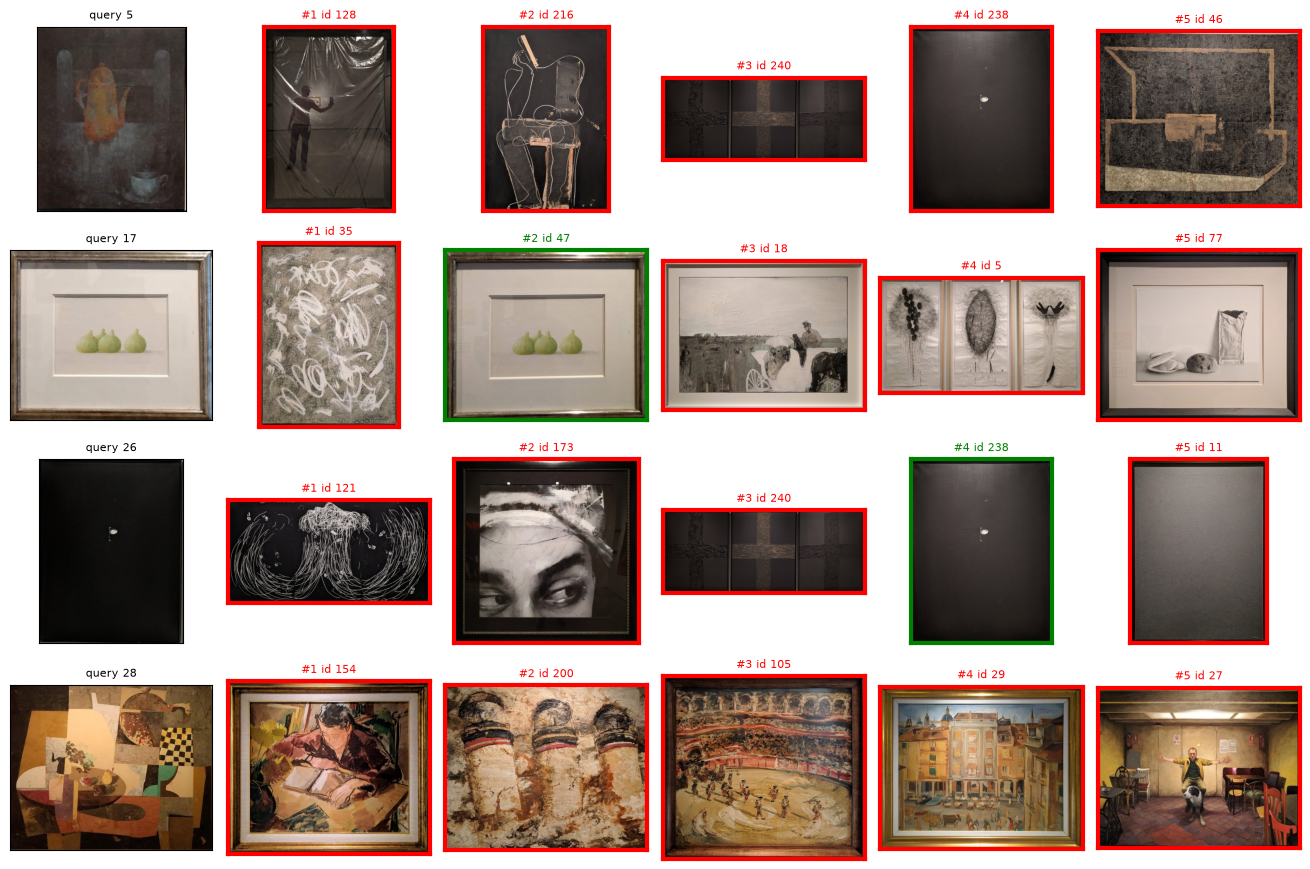

In [15]:
show_retrievals(store[best], q_imgs, db_imgs, train_dataset.ids, ground_truth, fails[:4])

Main causes: (1) colour and lighting differ between the query photo and the database photo, and histograms compare colour values directly; (2) dark paintings fall into the same few low-L bins; (3) the frame and the wall count as painting content. This motivates colour normalisation and background removal (Task 3) as the next steps.


Conclusion (Task 2): Block histograms (5x5, Lab, σ 0.5, weighted channels, Hellinger) improve our W1 result from mAP@1 0.700 / mAP@5 0.728 to 0.867 / 0.892 on QSD1. The gain comes from adding spatial information. The remaining errors come mainly from lighting changes and from frames or background in the photo.

## Task 3 - Removing background

Remove all the backgrounds of the images of /QST2_W2 using the background color (e.g. model background distribution, color
thresholds, …)

The implemented idea is:
1. Take a strip along the outer border of the image (4 % of the shorter side), which most likely belongs to the background.
2. Work with LAB hist but give less weight to lightness (L: 0.5). Lighting varies across a wall (gradients, shadows, exposure), whereas the wall colour does not.
3. Run k-means (k = 3) on the border pixels. The largest cluster is taken as the background colour. The other clusters are kept only if they cover at least 25 % of the border (e.g. a floor).
4. Model each kept cluster by its mean and its per-channel standard deviation.
5. For every pixel of the image, compute the weighted z-score distance to the closest background cluster.
6. Threshold this distance (Otsu on the log distance, clipped to [2, 6]). Pixels close to the background model are background and the rest are foreground.
7. Keep as background only the regions connected to the image border, so that wall-coloured areas inside the painting remain in the foreground.
8. Clean the mask (opening, closing, hole filling, removal of blobs smaller than 5 % of the image).
9. Compute the descriptor on the foreground pixels only (crop to the mask bounding box, masked histograms).

In [16]:
def border_strips(h, w, frac):
    """
    Step 1: marks the outer strip of the image, which most likely belongs to the background.

    Returns
    -------
    np.ndarray
        Boolean array of shape (h, w), True on a strip of width max(3, round(frac * min(h, w)))
        along the four image borders.
    """
    bw = max(3, int(round(frac * min(h, w))))
    m = np.zeros((h, w), bool)
    m[:bw], m[-bw:], m[:, :bw], m[:, -bw:] = True, True, True, True
    return m


def background_distance(lab, border, k=3, min_share=0.25, w_lab=(0.5, 1.0, 1.0), sigma_floor=(2.5, 1.5, 1.5)):
    """
    Steps 2-5: fits the background colour model on the border pixels (L-weighted k-means, mean and std per 
    cluster) and measures every pixel's distance to it.

    Returns
    -------
    np.ndarray
        Float32 array of shape (h, w) with the weighted z-score distance of each pixel to the
        closest kept background cluster (small = background-like).
    """
    wv = np.asarray(w_lab, np.float32)
    X = lab[border]
    K = min(k, len(X))
    cv2.setRNGSeed(0)                                    # deterministic
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.5)
    _, idx, _ = cv2.kmeans((X * wv).astype(np.float32), K, None, crit, 3,
                           cv2.KMEANS_PP_CENTERS)
    idx = idx.ravel()
    share = np.bincount(idx, minlength=K) / len(X)
    keep = [c for c in range(K) if share[c] >= min_share or c == share.argmax()]

    flat = lab.reshape(-1, 3)
    dist = np.full(flat.shape[0], np.inf, np.float32)
    for c in keep:
        pts = X[idx == c]
        mu = pts.mean(0)
        sd = np.maximum(pts.std(0), sigma_floor)
        d = np.sqrt((((flat - mu) / sd * wv) ** 2).sum(1))
        dist = np.minimum(dist, d)
    return dist.reshape(lab.shape[:2])


def adaptive_threshold(dist, tau_range=(2.0, 6.0)):
    """
    Step 6: chooses the background/foreground distance threshold with Otsu on log(1 + distance),
    clipped to tau_range.

    Returns
    -------
    float
        Threshold tau, in distance units and within tau_range; pixels with distance < tau
        are background candidates.
    """
    dmax = max(float(dist.max()), 1.0)
    scaled = np.clip(np.log1p(dist) / np.log1p(dmax) * 255, 0, 255).astype(np.uint8)
    t, _ = cv2.threshold(scaled, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    tau = np.expm1(t / 255 * np.log1p(dmax))
    return float(np.clip(tau, *tau_range))


def foreground_mask(img, work_size=400, border_frac=0.04, k=3, min_share=0.25,
                    w_lab=(0.5, 1.0, 1.0), sigma_floor=(2.5, 1.5, 1.5),
                    tau_range=(2.0, 6.0), morph_frac=0.012, min_area=0.05,
                    keep="all", rectangular=False, return_debug=False):
    """
    Steps 1-8: computes the colour-only binary foreground (painting) mask of 
    a BGR image, from background model to mask clean-up.

    Returns
    -------
    np.ndarray
        Boolean array of shape (H, W) (original image size), True on foreground pixels.
        If return_debug is True, returns (mask, dict(dist, tau, border)) instead.
    """
    H, W = img.shape[:2]
    s = min(1.0, work_size / max(H, W))
    small = cv2.resize(img, (max(1, round(W * s)), max(1, round(H * s))),
                       interpolation=cv2.INTER_AREA) if s < 1 else img
    small = cv2.GaussianBlur(small, (5, 5), 0)
    lab = cv2.cvtColor(small.astype(np.float32) / 255.0, cv2.COLOR_BGR2LAB)  # L 0..100, a/b ~ -127..127
    h, w = lab.shape[:2]

    border = border_strips(h, w, border_frac)
    dist = background_distance(lab, border, k, min_share, w_lab, sigma_floor)
    tau = adaptive_threshold(dist, tau_range)

    bg = (dist < tau).astype(np.uint8)
    _, cc = cv2.connectedComponents(bg, connectivity=4)
    touching = np.unique(cc[border & (bg > 0)])
    bg_conn = np.isin(cc, touching[touching > 0])
    fg = (~bg_conn).astype(np.uint8)

    ks = max(3, int(round(morph_frac * min(h, w))) | 1)
    ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ks, ks))
    fg = cv2.morphologyEx(fg, cv2.MORPH_OPEN, ker)
    fg = cv2.morphologyEx(fg, cv2.MORPH_CLOSE, ker)
    fg = binary_fill_holes(fg).astype(np.uint8)

    n, cc, stats, _ = cv2.connectedComponentsWithStats(fg, connectivity=8)
    areas = stats[1:, cv2.CC_STAT_AREA]
    labels = [i + 1 for i, a in enumerate(areas) if a >= min_area * h * w]
    if keep == "largest" and len(areas):
        labels = [1 + int(areas.argmax())]
    out = np.isin(cc, labels)

    if rectangular and out.any():                        # optional shape prior (not colour): report it as such
        rect = np.zeros_like(out)
        for l in labels:
            ys, xs = np.where(cc == l)
            rect[ys.min():ys.max() + 1, xs.min():xs.max() + 1] = True
        out = rect

    frac = out.mean()
    if frac < 0.05 or frac > 0.98:                       # degenerate -> keep everything
        out = np.ones((h, w), bool)

    mask = cv2.resize(out.astype(np.float32), (W, H), interpolation=cv2.INTER_LINEAR) > 0.5
    if return_debug:
        return mask, dict(dist=dist, tau=tau, border=border)
    return mask



def crop_to_mask(img, mask):
    """
    Step 9 (part): crops the image and its mask to the bounding box of the foreground, 
    so the block grid lies over the painting and not over the wall.

    Returns
    -------
    tuple[np.ndarray, np.ndarray]
        Cropped image and cropped boolean mask, both of shape (y1 - y0, x1 - x0).
    """
    ys, xs = np.where(mask)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    return img[y0:y1, x0:x1], mask[y0:y1, x0:x1]


def descriptor_masked(img, mask=None, levels=(5,), bins=48, sigma=0.5,
                      weights=(0.125, 0.5, 0.375), crop=True):
    """
    Step 9: computes the Task 2 block Lab histogram descriptor using only 
    foreground pixels, weighting each block by its foreground share.

    Returns
    -------
    np.ndarray
        Flattened array of length sum(level * level for level in levels) * 3 * bins that sums to 1
        (per level, reshape to (level * level, 3, bins) to get one row per block and channel).
    """
    if mask is None or not mask.any():
        mask = np.ones(img.shape[:2], bool)
    if crop:
        img, mask = crop_to_mask(img, mask)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    m8 = np.ascontiguousarray(mask.astype(np.uint8))
    h, w = m8.shape
    wts = np.asarray(weights, np.float32)

    out = []
    for level in levels:
        ye = np.linspace(0, h, level + 1, dtype=int)
        xe = np.linspace(0, w, level + 1, dtype=int)
        hist = np.zeros((level * level, 3, bins), np.float32)
        area = np.zeros(level * level, np.float32)
        for i in range(level):
            for j in range(level):
                b = i * level + j
                bm = np.ascontiguousarray(m8[ye[i]:ye[i + 1], xe[j]:xe[j + 1]])
                area[b] = bm.sum()
                if area[b] == 0:
                    continue
                blk = np.ascontiguousarray(lab[ye[i]:ye[i + 1], xe[j]:xe[j + 1]])
                for c in range(3):
                    hh = cv2.calcHist([blk], [c], bm, [bins], [0, 256]).ravel()
                    hist[b, c] = hh / max(hh.sum(), 1e-12)
        if sigma > 0:
            hist = gaussian_filter1d(hist, sigma, axis=2, mode="nearest")
            hist /= np.maximum(hist.sum(axis=2, keepdims=True), 1e-12)
        hist *= (area / area.sum())[:, None, None]          # foreground-area weight
        hist *= wts[None, :, None]                          # L, a, b weights
        out.append(hist.ravel() / hist.sum())
    return np.concatenate(out) / len(levels)


### Evaluation

- Create a binary mask to evaluate the method
- Compute the descriptors on the foreground pixels.

In [17]:
MASK_DIR = Path("./assets/masks_qst2_w2") # store the masks to evaluate
MASK_DIR.mkdir(exist_ok=True)

qst2 = load_image_dataset("../data/qst_w2/qst2_w2")
qst2_imgs = [read(p) for p in qst2.paths]
qst2_masks = [foreground_mask(im) for im in qst2_imgs]

# Binary masks (255 = painting, 0 = background), one PNG per image with the same
for p, m in zip(qst2.paths, qst2_masks):
    cv2.imwrite((MASK_DIR / f"{p.stem}.png").as_posix(), m.astype(np.uint8) * 255)

print(len(qst2_imgs), "masks saved in", MASK_DIR)
print("foreground fraction: min %.2f  median %.2f  max %.2f" % tuple(
    np.percentile([m.mean() for m in qst2_masks], [0, 50, 100])))

30 masks saved in assets\masks_qst2_w2
foreground fraction: min 0.14  median 0.53  max 0.81


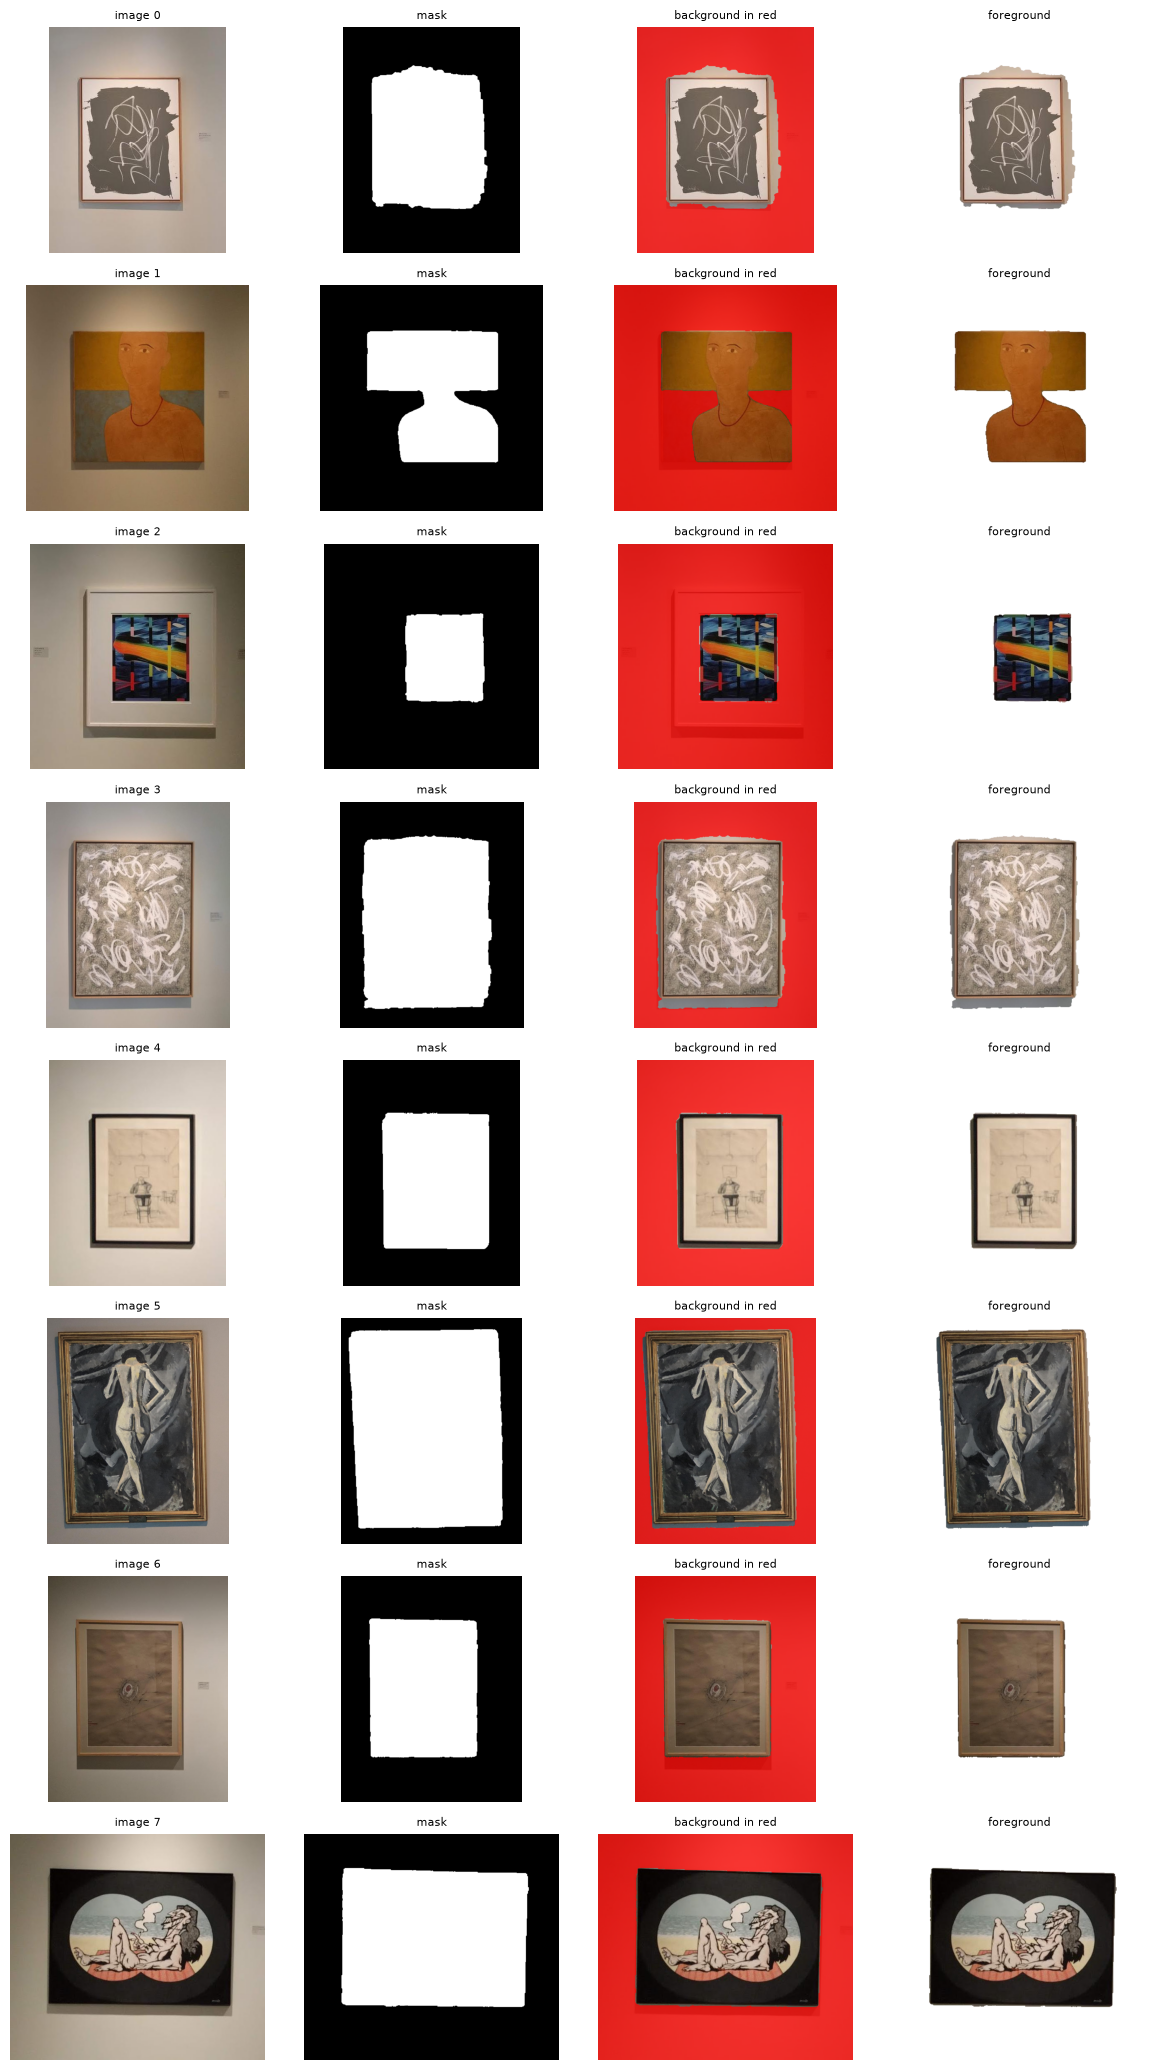

In [18]:
def show_masks(imgs, masks, idx, ncols=4):
    n = len(idx)
    fig, axes = plt.subplots(n, ncols, figsize=(3 * ncols, 2.6 * n))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(idx):
        im, m = imgs[i], masks[i]
        rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        overlay = rgb.copy()
        overlay[~m] = (0.25 * overlay[~m] + 0.75 * np.array([255, 0, 0])).astype(np.uint8)
        cut = rgb.copy(); cut[~m] = 255
        for ax, x, t in zip(axes[r], [rgb, m, overlay, cut],
                            [f"image {i}", "mask", "background in red", "foreground"]):
            ax.imshow(x, cmap="gray" if x.ndim == 2 else None); ax.set_title(t, fontsize=8); ax.axis("off")
    plt.tight_layout(); plt.show()

show_masks(qst2_imgs, qst2_masks, list(range(0, min(8, len(qst2_imgs)))))

# Task 4 - Background removal evaluation

Mask evaluation using precision, recall and F1-measure